In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("ea_fc26_outfield.csv")

In [3]:
df.head()

,id,rank,overallRating,firstName,lastName,commonName,birthdate,height,weight,skillMoves,...,composure,interceptions,defensiveAwareness,standingTackle,slidingTackle,headingAccuracy,aggression,jumping,stamina,strength
0,209331,1,91,Mohamed,Salah,NaN,1992-06-15,175,72,4,...,93,55,38,43,41,59,63,79,88,75
1,231747,3,91,Kylian,Mbappé,NaN,1998-12-20,182,75,5,...,88,38,26,34,32,78,61,90,83,77
2,231443,5,90,Ousmane,Dembélé,NaN,1997-05-15,178,67,5,...,88,45,49,49,39,74,58,84,76,69
3,231866,6,90,Rodrigo,Hernández Cascante,Rodri,1996-06-22,190,82,3,...,93,84,88,87,82,81,85,83,91,83
4,203376,8,90,Virgil,van Dijk,NaN,1991-07-08,193,92,2,...,90,91,91,91,87,88,85,89,75,93


In [4]:
df.describe()

,id,rank,overallRating,height,weight,skillMoves,weakFootAbility,preferredFoot,age,pac,...,composure,interceptions,defensiveAwareness,standingTackle,slidingTackle,headingAccuracy,aggression,jumping,stamina,strength
count,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,...,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000,14412.000000
mean,215831.500000,9223.009506,66.436234,181.184846,74.489453,2.549126,2.996808,1.259714,26.056828,68.539065,...,60.752429,51.504996,51.252012,53.419928,50.886275,56.977380,60.295934,67.587011,67.709270,66.028865
std,68676.718992,4996.338826,6.705697,6.573749,6.625448,0.637908,0.650385,0.438493,4.570199,10.690396,...,9.832031,18.266538,17.507679,17.867077,17.892218,11.380722,12.943960,11.414053,11.149354,12.258600
min,20801.000000,1.000000,47.000000,155.000000,47.000000,2.000000,1.000000,1.000000,17.000000,30.000000,...,30.000000,10.000000,10.000000,10.000000,10.000000,24.000000,24.000000,27.000000,27.000000,28.000000
25%,210507.000000,5039.750000,62.000000,177.000000,70.000000,2.000000,3.000000,1.000000,22.000000,62.000000,...,54.000000,36.000000,38.000000,39.000000,36.000000,49.000000,52.000000,61.000000,61.000000,58.000000
50%,241853.000000,9324.500000,66.000000,181.000000,74.000000,2.000000,3.000000,1.000000,26.000000,69.000000,...,61.000000,58.000000,56.000000,60.000000,57.000000,58.000000,62.000000,69.000000,68.000000,67.000000
75%,262070.250000,13468.250000,71.000000,186.000000,79.000000,3.000000,3.000000,2.000000,29.000000,76.000000,...,68.000000,65.000000,65.000000,67.000000,65.000000,65.000000,70.000000,76.000000,75.000000,75.000000
max,279948.000000,17873.000000,91.000000,206.000000,104.000000,5.000000,5.000000,2.000000,44.000000,97.000000,...,93.000000,91.000000,91.000000,91.000000,89.000000,93.000000,94.000000,95.000000,95.000000,95.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14412 entries, 0 to 14411
Data columns (total 56 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  14412 non-null  int64 
 1   rank                14412 non-null  int64 
 2   overallRating       14412 non-null  int64 
 3   firstName           14412 non-null  object
 4   lastName            14412 non-null  object
 5   commonName          2114 non-null   object
 6   birthdate           14412 non-null  object
 7   height              14412 non-null  int64 
 8   weight              14412 non-null  int64 
 9   skillMoves          14412 non-null  int64 
 10  weakFootAbility     14412 non-null  int64 
 11  preferredFoot       14412 non-null  int64 
 12  position            14412 non-null  object
 13  positionType        14412 non-null  object
 14  alternatePositions  10485 non-null  object
 15  nationality         14412 non-null  object
 16  team                14

In [7]:
df.isna().sum()

id                        0
rank                      0
overallRating             0
firstName                 0
lastName                  0
commonName            12298
birthdate                 0
height                    0
weight                    0
skillMoves                0
weakFootAbility           0
preferredFoot             0
position                  0
positionType              0
alternatePositions     3927
nationality               0
team                      0
leagueName                0
playStyles             7751
playStylesPlus        14303
age                       0
pac                       0
sho                       0
pas                       0
dri                       0
def                       0
phy                       0
acceleration              0
sprintSpeed               0
finishing                 0
shotPower                 0
longShots                 0
volleys                   0
penalties                 0
positioning               0
shortPassing        

In [39]:
features=['pac','sho','pas','dri','def','phy']
X=df[features]
y=df['overallRating']

In [40]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [41]:
from sklearn.linear_model import LinearRegression
linear=LinearRegression()
linear.fit(X_train,y_train)
pred=linear.predict(X_test)

In [42]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,pred)
n=X_test.shape[0]
k=X_test.shape[1]
adj_r2=1-((n-1)*(1-r2)/(n-k-1))
print(r2)
print(adj_r2)

0.7563807524731655
0.7558725064769343


In [47]:
from sklearn.tree import DecisionTreeRegressor
tree=DecisionTreeRegressor(random_state=42,criterion='absolute_error',max_depth=None,min_samples_leaf=5,min_samples_split=20)
tree.fit(X_train,y_train)
predt=tree.predict(X_test)
r2t=r2_score(y_test,predt)
print(r2t)

0.9438780166048921


In [44]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 10, 20, 50],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['squared_error', 'absolute_error']
}
grid_search = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error', 
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)
print(grid_search.best_params_)

Fitting 5 folds for each of 160 candidates, totalling 800 fits
{'criterion': 'absolute_error', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 20}


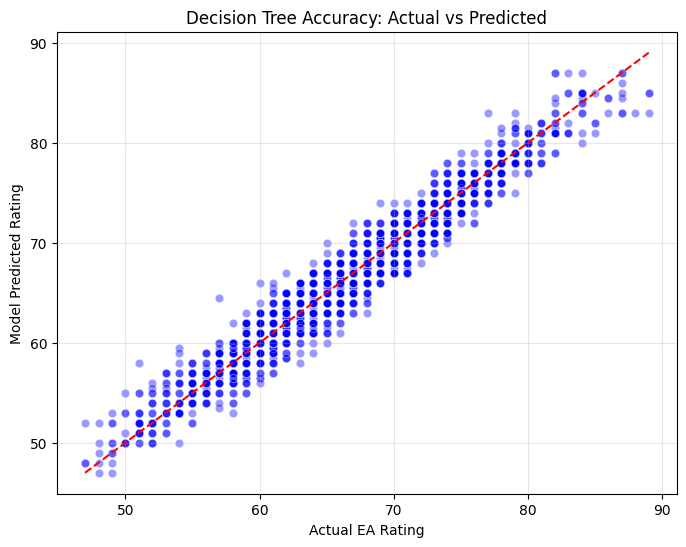

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=predt, alpha=0.4, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--")
plt.xlabel("Actual EA Rating")
plt.ylabel("Model Predicted Rating")
plt.title("Decision Tree Accuracy: Actual vs Predicted")
plt.grid(True, alpha=0.3)
plt.show()

In [49]:
import pandas as pd

# 1. Create the comparison DataFrame
comparison_df = pd.DataFrame({
    'First Name': df.loc[X_test.index, 'firstName'],
    'Last Name': df.loc[X_test.index, 'lastName'],
    'Actual Rating': y_test,
    'Predicted Rating': predt
})

# 2. Calculate the Difference
comparison_df['Difference'] = (comparison_df['Actual Rating'] - comparison_df['Predicted Rating']).round(1)

# 3. Calculate the Absolute Difference (so -5 and +5 are both treated as a 5-point error)
comparison_df['Abs_Difference'] = comparison_df['Difference'].abs()

# 4. Sort to find the worst predictions
worst_predictions = comparison_df.sort_values(by='Abs_Difference', ascending=False).head(10)

# 5. Display the result
display(worst_predictions[['First Name', 'Last Name', 'Actual Rating', 'Predicted Rating', 'Difference']])

,First Name,Last Name,Actual Rating,Predicted Rating,Difference
13112,Shiyuan,Yang,57,64.5,-7.5
14186,Lachlan,Middleton,51,58.0,-7.0
11908,Mohamed,Ofkir,60,66.0,-6.0
927,Daley,Blind,77,83.0,-6.0
8,Achraf,Hakimi,89,83.0,6.0
13835,Jitendra,Singh,54,59.5,-5.5
6186,Aljoša,Vasić,67,72.0,-5.0
221,John,Stones,82,87.0,-5.0
5963,Berkay,Yilmaz,68,63.0,5.0
9722,Fabrizio,Sartori,64,59.0,5.0
